In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("pjme_hourly.csv")
df["Datetime"] = pd.to_datetime(df["Datetime"])

display(df)

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0
...,...,...
145361,2018-01-01 20:00:00,44284.0
145362,2018-01-01 21:00:00,43751.0
145363,2018-01-01 22:00:00,42402.0
145364,2018-01-01 23:00:00,40164.0


In [26]:
print(df.shape)
# print(df.describe)
print("duplicates: ",df.duplicated().sum())
print("non existing: ", df.isna().sum())

df = df.sort_index()

Q1 = df['PJME_MW'].quantile(0.25)
Q3 = df['PJME_MW'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['PJME_MW'] < lower_bound) | (df['PJME_MW'] > upper_bound)]
print("number of outliers is: ", len(outliers))

df['hourly_diff'] = df['PJME_MW'].diff().abs()

sudden_jumps = df[df['hourly_diff'] > 5000]

print("number of anamolies: ", len(sudden_jumps))

(145366, 3)
duplicates:  0
non existing:  Datetime       0
PJME_MW        0
hourly_diff    1
dtype: int64
number of outliers is:  3455
number of anamolies:  4


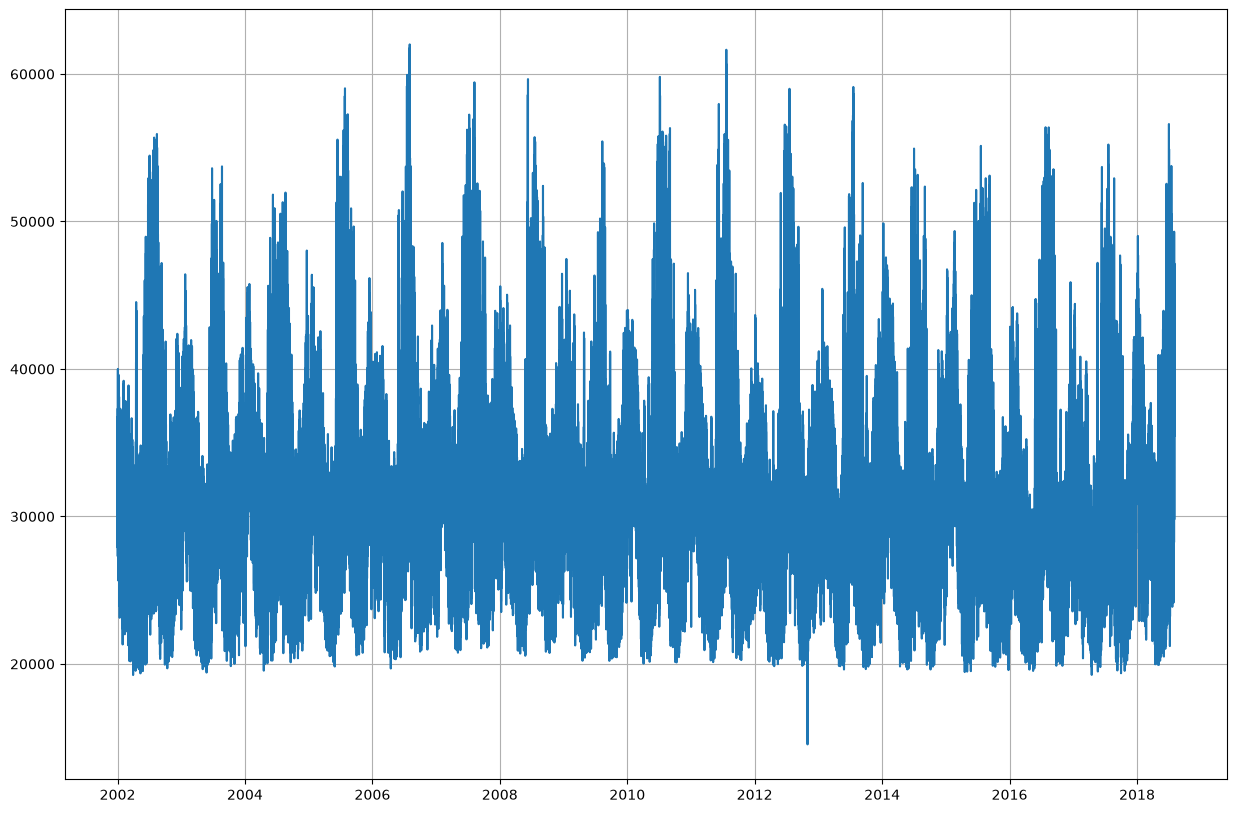

In [ ]:
plt.figure(figsize=(15, 10))
plt.plot(df['Datetime'], df['PJME_MW'])
plt.grid(True)
plt.show()

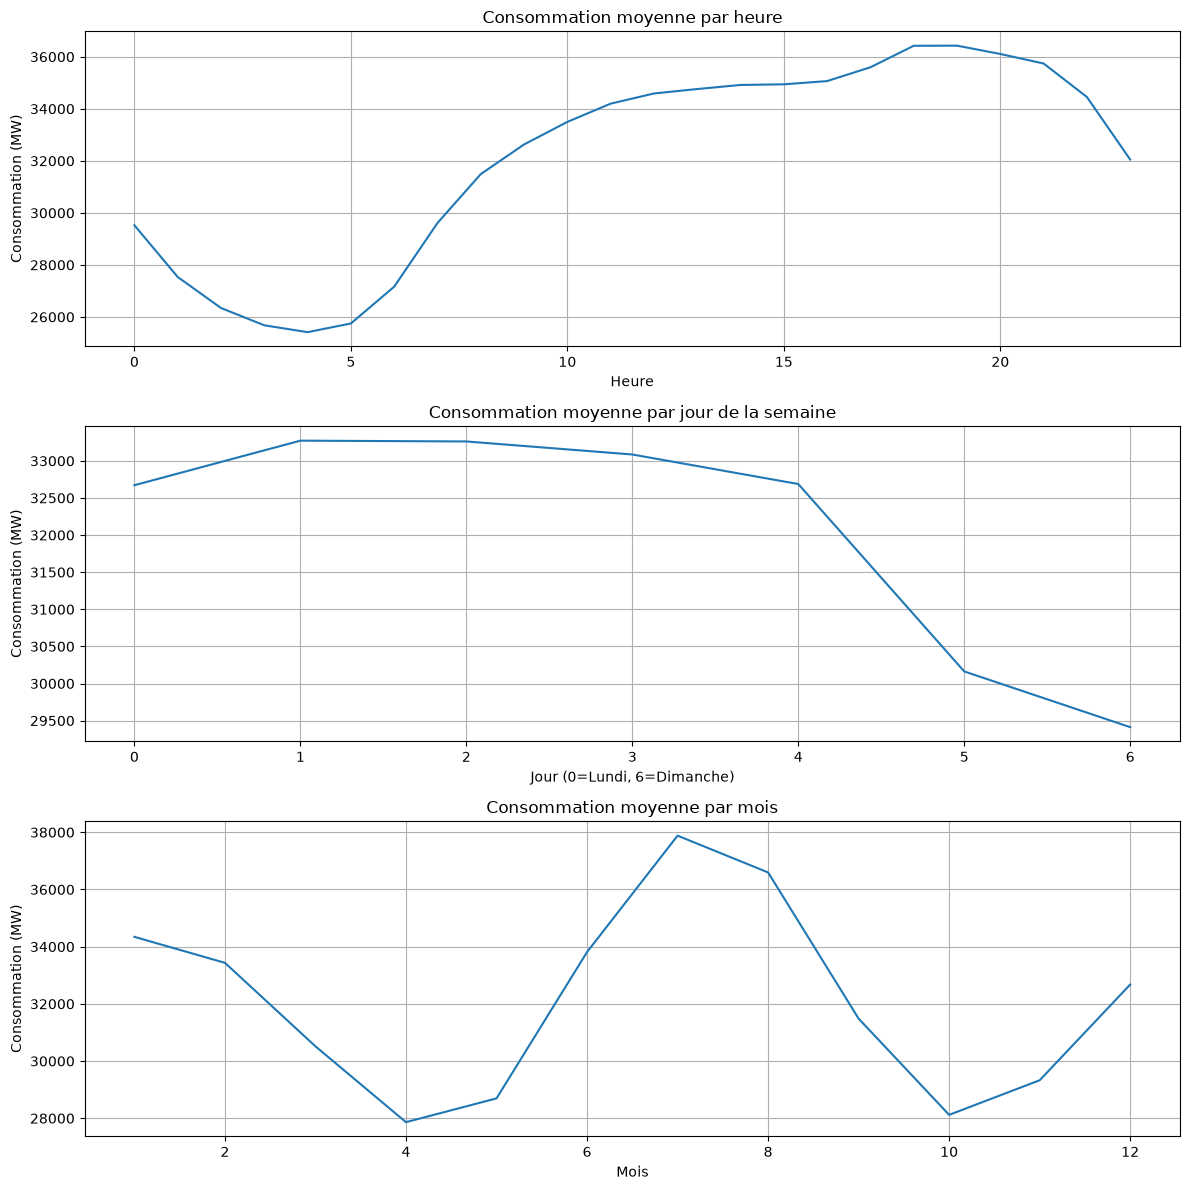

In [ ]:
df['Hour'] = df['Datetime'].dt.hour
df['Day'] = df['Datetime'].dt.dayofweek
df['Month'] = df['Datetime'].dt.month

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

df.groupby('Hour')['PJME_MW'].mean().plot(ax=axes[0])
axes[0].set_title("Consommation moyenne par heure")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Consommation")
axes[0].grid(True)

df.groupby('Day')['PJME_MW'].mean().plot(ax=axes[1])
axes[1].set_title("Consommation moyenne par jour de la semaine")
axes[1].set_xlabel("Jour (0=Lundi, 6=Dimanche)")
axes[1].set_ylabel("Consommation")
axes[1].grid(True)

df.groupby('Month')['PJME_MW'].mean().plot(ax=axes[2])
axes[2].set_title("Consommation moyenne par mois")
axes[2].set_xlabel("Mois")
axes[2].set_ylabel("Consommation")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [33]:
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.dayofweek
df['Month'] = df['Datetime'].dt.month
df['Year'] = df['Datetime'].dt.year
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)

df['lag_24'] = df['PJME_MW'].shift(24)
df['lag_168'] = df['PJME_MW'].shift(168)

df['roll_24'] = df['PJME_MW'].shift(1).rolling(24).mean()

df = df.dropna(subset=['lag_24', 'lag_168', 'roll_24'])
df = df.reset_index(drop=True)

In [ ]:
features = [
    'Hour', 'DayOfWeek', 'Month', 'Year',
    'IsWeekend', 'lag_24', 'lag_168', 'roll_24'
]

X = df[features]
y = df['PJME_MW']

print(df)

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

                  Datetime  PJME_MW  hourly_diff  Hour  Day  Month  DayOfWeek  \
0      2002-01-08 01:00:00  29445.0       1742.0     1    1      1          1   
1      2002-01-08 02:00:00  28670.0        775.0     2    1      1          1   
2      2002-01-08 03:00:00  28375.0        295.0     3    1      1          1   
3      2002-01-08 04:00:00  28542.0        167.0     4    1      1          1   
4      2002-01-08 05:00:00  29261.0        719.0     5    1      1          1   
...                    ...      ...          ...   ...  ...    ...        ...   
145193 2018-08-02 20:00:00  44057.0       1584.0    20    3      8          3   
145194 2018-08-02 21:00:00  43256.0        801.0    21    3      8          3   
145195 2018-08-02 22:00:00  41552.0       1704.0    22    3      8          3   
145196 2018-08-02 23:00:00  38500.0       3052.0    23    3      8          3   
145197 2018-08-03 00:00:00  35486.0       3014.0     0    4      8          4   

        Year  IsWeekend   l